        size   mean  median
annee                      
2022   33923   77.4    43.4
2023   16789  147.1    75.1
2024   33406  166.9   114.2
2025   33384  187.4   142.9


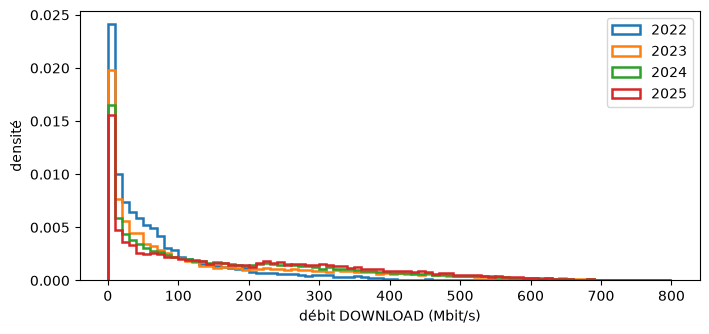

In [3]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.base import clone
from xgboost import XGBRegressor

from evaluation import scores_regression

h = pd.read_parquet("../data/processed/arcep_2022_2025.parquet")
dl = h.query("protocole == 'DOWNLOAD'").copy()
y = dl["bitrate_dl"]
annee = dl["annee"]

print(dl.groupby("annee")["bitrate_dl"].agg(["size", "mean", "median"]).round(1))

fig, ax = plt.subplots(figsize=(8, 3.5))
for a in [2022, 2023, 2024, 2025]:
    ax.hist(y[annee == a], bins=80, range=(0, 800), histtype="step", lw=1.8, density=True, label=str(a))
ax.set_xlabel("débit DOWNLOAD (Mbit/s)")
ax.set_ylabel("densité")
ax.legend()
plt.show()

In [4]:
dl["classe_rsrp"] = pd.cut(dl["rsrp"], [-200, -110, -100, -90, 0])
dl.pivot_table(index="classe_rsrp", columns="annee", values="bitrate_dl",
               aggfunc="median", observed=True).round(1)

annee,2022,2023,2024,2025
classe_rsrp,,,,
"(-200, -110]",20.0,25.9,31.2,40.8
"(-110, -100]",42.4,99.7,131.0,163.7
"(-100, -90]",76.4,202.0,237.8,275.2
"(-90, 0]",122.5,224.8,306.2,331.3


In [5]:
entr_val = annee <= 2024
test = annee == 2025

def bilan(y_vrai, y_pred):
    s = scores_regression(y_vrai, y_pred)
    s["biais"] = np.mean(y_pred - y_vrai)
    return {k: round(float(v), 3) for k, v in s.items()}

resultats = {}

# 1. Toujours prédire la médiane de 2022-2024
mediane = y[entr_val].median()
resultats["médiane globale"] = bilan(y[test], np.full(test.sum(), mediane))

# 2. Médiane par zone et par opérateur, apprise sur 2022-2024
table = dl[entr_val].groupby(["zone", "operator"])["bitrate_dl"].median()
cles = pd.MultiIndex.from_frame(dl.loc[test, ["zone", "operator"]])
resultats["médiane zone × opérateur"] = bilan(y[test], table.reindex(cles).to_numpy())

pd.DataFrame(resultats).T

,MAE,RMSE,R2,biais
médiane globale,152.78,210.650,-0.494,-121.093
médiane zone × opérateur,131.27,181.384,-0.107,-96.771


In [6]:
from variables import ajouter_precedent

dl = ajouter_precedent(dl, "bitrate_dl", "debit_prec", delai_max=3600)

CATEGORIES = ["operator", "zone", "situation"]
JEUX = {
    "base":              (["rsrp", "heure"], ["rsrp_absent"]),
    "+ débit précédent": (["rsrp", "heure", "debit_prec"], ["rsrp_absent", "debit_prec_absent"]),
}

def fabriquer(nom_modele, numeriques, booleennes):
    if nom_modele == "linéaire":
        prep = ColumnTransformer([
            ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                              ("echelle", StandardScaler())]), numeriques),
            ("bool", "passthrough", booleennes),
            ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORIES)])
        reg = LinearRegression()
    else:
        prep = ColumnTransformer([
            ("num", "passthrough", numeriques + booleennes),
            ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORIES)])
        reg = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6,
                           n_jobs=-1, random_state=0)
    return Pipeline([("prep", prep), ("reg", reg)])

for jeu, (numeriques, booleennes) in JEUX.items():
    X = dl[numeriques + booleennes + CATEGORIES]
    for nom_modele in ["linéaire", "xgboost"]:
        modele = fabriquer(nom_modele, numeriques, booleennes).fit(X[entr_val], y[entr_val])
        resultats[(jeu, nom_modele)] = bilan(y[test], modele.predict(X[test]))

print("Part des tests avec un débit précédent :", round(dl["debit_prec"].notna().mean(), 3))
pd.DataFrame(resultats).T

Part des tests avec un débit précédent : 0.555


,MAE,RMSE,R2,biais
médiane globale,152.780,210.650,-0.494,-121.093
médiane zone × opérateur,131.270,181.384,-0.107,-96.771
"(base, linéaire)",110.428,146.744,0.275,-62.016
"(base, xgboost)",102.321,142.420,0.317,-61.486
"(+ débit précédent, linéaire)",81.128,115.557,0.551,-36.461
"(+ débit précédent, xgboost)",70.065,107.080,0.614,-32.338


In [7]:
numeriques, booleennes = JEUX["+ débit précédent"]
X = dl[numeriques + booleennes + CATEGORIES]
modele = fabriquer("xgboost", numeriques, booleennes)

moitie = np.random.default_rng(0).random(test.sum()) < 0.5
X_t, y_t = X[test], y[test]

strategies = {
    "2022-2024": annee <= 2024,
    "2024 seule": annee == 2024,
}
comparaison = {}
for nom, masque in strategies.items():
    m = clone(modele).fit(X[masque], y[masque])
    comparaison[nom] = bilan(y_t[~moitie], m.predict(X_t[~moitie]))

m = clone(modele).fit(X_t[moitie], y_t[moitie])
comparaison["intra-2025 (sans dérive)"] = bilan(y_t[~moitie], m.predict(X_t[~moitie]))

pd.DataFrame(comparaison).T

,MAE,RMSE,R2,biais
2022-2024,69.982,107.257,0.611,-31.564
2024 seule,65.769,98.740,0.671,-14.314
intra-2025 (sans dérive),65.759,96.566,0.685,1.093


In [8]:
pd.DataFrame(resultats).T.to_csv("../results/tables/debit_regression_test_2025.csv")
pd.DataFrame(comparaison).T.to_csv("../results/tables/debit_strategies_entrainement.csv")